# Practical 2 – Quantum Teleportation

**Problem Statement:** Implement the Quantum Teleportation algorithm in Python.

**Objective:**
1. Understand the Quantum Teleportation algorithm
2. Create a quantum circuit
3. Understand how to perform entanglement

**Outcome:** Displays the circuit for Quantum Teleportation.

**Theory:** Because of the **no-cloning theorem** a quantum state cannot be copied. Instead it can be *teleported*:
Sharanya (sender) and Kartik (receiver) share an entangled **Bell pair**. Sharanya entangles her unknown qubit |ψ⟩ = α|0⟩ + β|1⟩
with her half of the pair, measures her two qubits and sends the 2 classical bits to Kartik. Depending on the bits Kartik applies

| Bits (q1 q0) | Gate on Kartik's qubit |
|---|---|
| 00 | I |
| 01 | X |
| 10 | Z |
| 11 | ZX |

after which his qubit is in exactly the state |ψ⟩.

**Algorithm**
1. Create a Bell pair between q1 (Sharanya) and q2 (Kartik): H on q1, CNOT q1→q2
2. Sharanya applies CNOT ψ(q0)→q1, then H on q0
3. Sharanya measures q0, q1 into classical bits and sends them to Kartik
4. Kartik applies X (if q1-bit = 1) and Z (if q0-bit = 1)

In [1]:
# Run this cell first in Google Colab (installs Qiskit + simulator)
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\jadha\AppData\Local\Temp\claude\efb368ed25e968d0\a89940ab-0696-4fca-91e1-025ecd80d2c1\scratchpad\qenv\Scripts\python.exe -m pip install --upgrade pip


State to teleport |psi> = [0.7753-0.283j  0.5304+0.1936j]


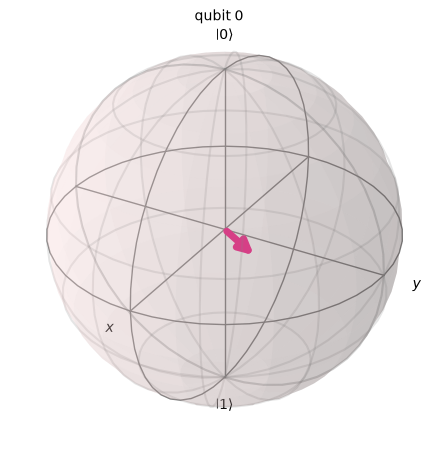

In [2]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, random_statevector, partial_trace, state_fidelity
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_aer import AerSimulator

# The unknown state Sharanya wants to send: |psi> = RY(theta) RZ(phi) |0>
theta, phi = 1.2, 0.7
psi_circ = QuantumCircuit(1, name="psi")
psi_circ.ry(theta, 0)
psi_circ.rz(phi, 0)
psi = Statevector(psi_circ)
print("State to teleport |psi> =", np.round(psi.data, 4))
plot_bloch_multivector(psi)

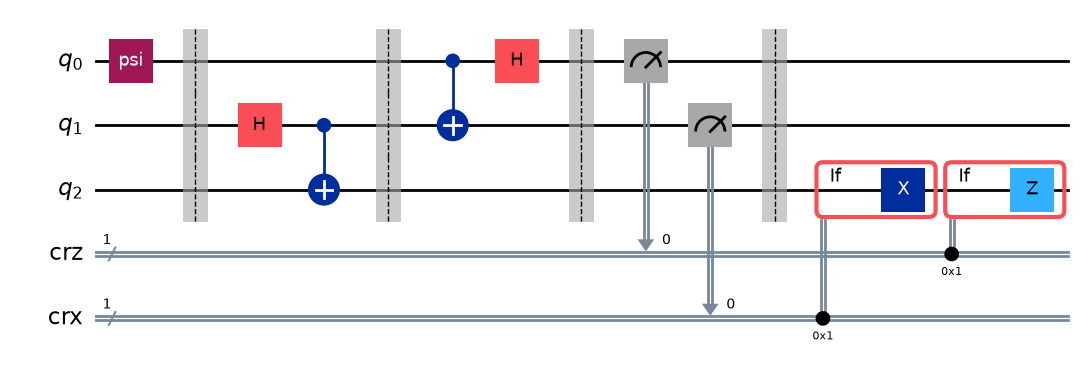

In [3]:
def teleportation_circuit():
    q = QuantumRegister(3, "q")          # q0 = psi (Sharanya), q1 = Sharanya's half, q2 = Kartik's half
    crz = ClassicalRegister(1, "crz")    # result of measuring q0
    crx = ClassicalRegister(1, "crx")    # result of measuring q1
    qc = QuantumCircuit(q, crz, crx)

    # Step 0: prepare the state to send on q0
    qc.append(psi_circ.to_gate(), [0])
    qc.barrier()

    # Step 1: the 'portal' creates a Bell pair between q1 and q2
    qc.h(1)
    qc.cx(1, 2)
    qc.barrier()

    # Step 2: Sharanya entangles psi with her half of the Bell pair
    qc.cx(0, 1)
    qc.h(0)
    qc.barrier()

    # Step 3: Sharanya measures her two qubits (classical bits sent to Kartik)
    qc.measure(0, crz)
    qc.measure(1, crx)
    qc.barrier()

    # Step 4: Kartik applies corrections depending on the classical bits
    with qc.if_test((crx, 1)):
        qc.x(2)
    with qc.if_test((crz, 1)):
        qc.z(2)
    return qc

tele = teleportation_circuit()
tele.draw('mpl')

### Verification 1 – Kartik's qubit equals |ψ⟩
We save the statevector at the end and trace out Sharanya's qubits. The fidelity with |ψ⟩ should be **1.0**
whatever the measurement result was.

In [4]:
sim = AerSimulator()
for run in range(4):
    qc = teleportation_circuit()
    qc.save_statevector()
    res = sim.run(transpile(qc, sim), shots=1, memory=True).result()
    final = res.get_statevector()
    kartik = partial_trace(final, [0, 1])          # keep only q2
    print(f"Run {run+1}: measured bits (crx crz) = {res.get_memory()[0]}, "
          f"fidelity(Kartik's qubit, psi) = {state_fidelity(kartik, psi):.6f}")

Run 1: measured bits (crx crz) = 1 1, fidelity(Kartik's qubit, psi) = 1.000000
Run 2: measured bits (crx crz) = 1 0, fidelity(Kartik's qubit, psi) = 1.000000


Run 3: measured bits (crx crz) = 0 1, fidelity(Kartik's qubit, psi) = 1.000000
Run 4: measured bits (crx crz) = 1 1, fidelity(Kartik's qubit, psi) = 1.000000


### Verification 2 – Undo the preparation on Kartik's qubit
If teleportation worked, applying the inverse of the preparation to q2 brings it back to |0⟩, so measuring q2 gives **0 in 100 % of shots**.

Measurement of Kartik's qubit after undoing psi: {'0': 2048}


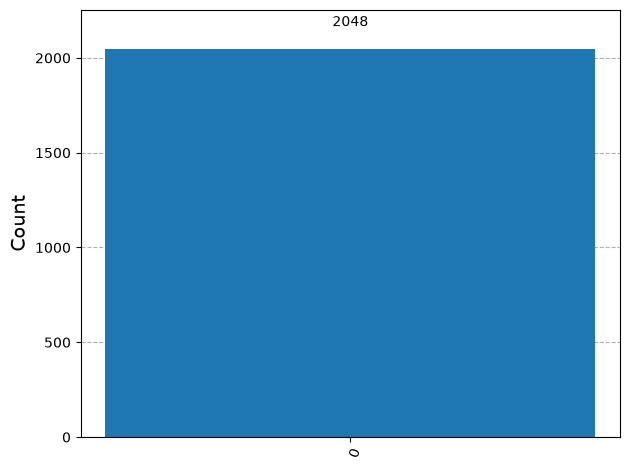

In [5]:
qc = teleportation_circuit()
check = ClassicalRegister(1, "result")
qc.add_register(check)
qc.append(psi_circ.inverse().to_gate(), [2])
qc.measure(2, check)

counts = sim.run(transpile(qc, sim), shots=2048).result().get_counts()
# the left-most bit in each key is the 'result' register
q2_counts = {}
for key, c in counts.items():
    q2_counts[key.split()[0]] = q2_counts.get(key.split()[0], 0) + c
print("Measurement of Kartik's qubit after undoing psi:", q2_counts)
plot_histogram(q2_counts)

**Conclusion:** Using a Bell pair (entanglement), two classical bits and conditional X/Z corrections, the unknown state |ψ⟩
was transferred from Sharanya's qubit q0 to Kartik's qubit q2 with fidelity 1, without copying it (no-cloning theorem respected).